# cancer_immune

PhysiCell's `PhysiCell/sample_projects/cancer_immune` as a **self-contained notebook**. The model below is Python,
generated from that project's XML and rules CSV; nothing here reads a PhysiCell
file, builds an executable or parses an output folder.

| | |
|---|---|
| domain | 75 x 75 x 75 voxels, dx=20 um, 3D |
| substrates | oxygen, immunostimulatory factor |
| cell types | cancer cell, immune cell |
| rules | 0 (0 runnable here) |
| initial cells | 28959 |

**Sections 3 to 7 are the point of the library**: each one is something the
XML-and-executable workflow cannot do at all, or can only do by editing C++,
recompiling and re-running from t=0.


In [1]:
import pathlib
import numpy as np, matplotlib.pyplot as plt
import pyphysicell as pc
from pyphysicell import viz

# the data this notebook needs sits next to it
DATA = next(p for p in (pathlib.Path('data'), pathlib.Path('notebooks/data'))
            if p.exists())
print('kernels:', pc.BACKEND, '|', pc.MAX_THREADS, 'threads', '| data:', DATA)

kernels: std::thread | 2 threads | data: data


## 1. The model is an object

Not a document to be parsed at start-up: a value you can read, edit, copy, hash
and generate. Everything below came from the project's XML.

In [2]:
# Generated by pyphysicell.codegen from PhysiCell/sample_projects/cancer_immune.
# Values are PhysiCell's: minutes, microns, and each substrate's own units.


model = pc.Model(name="cancer_immune")
model.domain = pc.Domain(x_min=-750.0, x_max=750.0, y_min=-750.0, y_max=750.0, z_min=-750.0, z_max=750.0, dx=20.0, dy=20.0, dz=20.0, use_2D=False)
model.time = pc.Time(dt_diffusion=0.01, dt_mechanics=0.1, dt_phenotype=6.0, max_time=30240.0, time_units="min", space_units="micron")
model.random_seed = 0
model.virtual_wall = True
model.omp_num_threads = 12
model.calculate_gradients = True
model.track_internalized_substrates = False
model.disable_automated_spring_adhesions = True
model.legacy_division_orientation = False
model.save = pc.SaveOptions(folder="output", full_interval=60.0, full_enabled=True, svg_interval=60.0, svg_enabled=True)

# --- substrates --------------------------------------------------------------
model.substrates = [
    pc.Substrate(
        "oxygen",
        diffusion_coefficient=100000.0,
        decay_rate=0.1,
        initial_condition=38.0,
        dirichlet_enabled=True, dirichlet_value=38.0,
        dirichlet_faces={"xmax": (True, 38.0), "xmin": (True, 38.0), "ymax": (True, 38.0), "ymin": (True, 38.0), "zmax": (True, 38.0), "zmin": (True, 38.0)},
    ),
    pc.Substrate(
        "immunostimulatory factor",
        diffusion_coefficient=1000.0,
        decay_rate=0.016,
        initial_condition=0.0,
        dirichlet_enabled=False, dirichlet_value=0.0,
        dirichlet_faces={"xmax": (False, 0.0), "xmin": (False, 0.0), "ymax": (False, 0.0), "ymin": (False, 0.0), "zmax": (False, 0.0), "zmin": (False, 0.0)},
    ),
]

# --- cell types --------------------------------------------------------------
ct0 = pc.CellType("cancer cell", ID=0)
ct0.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.00072},
         fixed_duration={(0, 0): False})
ct0.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct0.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct0.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0)
ct0.motility = pc.Motility(speed=0.25, persistence_time=5.0, migration_bias=0.5, enabled=False, use_2D=False, chemotaxis_enabled=False, chemotaxis_substrate="immunostimulatory factor", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False)
ct0.secretion = {
    "oxygen": pc.SecretionEntry(secretion_rate=0.0, secretion_target=38.0, uptake_rate=10.0, net_export_rate=0.0),
    "immunostimulatory factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct0.custom_data = {"oncoprotein": 1.0, "elastic_coefficient": 0.01, "kill_rate": 0.06667, "attachment_lifetime": 60.0, "attachment_rate": 0.2, "oncoprotein_saturation": 2.0, "oncoprotein_threshold": 0.5, "max_attachment_distance": 18.0, "min_attachment_distance": 14.0}
ct0.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=30.0,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={},
    attack_rates={},
    fusion_rates={},
    transformation_rates={},
    immunogenicities={})
ct0.custom_conserved = {"oncoprotein": False, "elastic_coefficient": False, "kill_rate": False, "attachment_lifetime": False, "attachment_rate": False, "oncoprotein_saturation": False, "oncoprotein_threshold": False, "max_attachment_distance": False, "min_attachment_distance": False}

ct1 = pc.CellType("immune cell", ID=1)
ct1.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct1.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct1.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct1.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0)
ct1.motility = pc.Motility(speed=1.0, persistence_time=10.0, migration_bias=0.5, enabled=True, use_2D=False, chemotaxis_enabled=False, chemotaxis_substrate="immunostimulatory factor", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False)
ct1.secretion = {
    "oxygen": pc.SecretionEntry(secretion_rate=0.0, secretion_target=38.0, uptake_rate=10.0, net_export_rate=0.0),
    "immunostimulatory factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct1.custom_data = {"oncoprotein": 0.0, "elastic_coefficient": 0.01, "kill_rate": 0.06667, "attachment_lifetime": 60.0, "attachment_rate": 0.2, "oncoprotein_saturation": 2.0, "oncoprotein_threshold": 0.5, "max_attachment_distance": 18.0, "min_attachment_distance": 14.0}
ct1.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=30.0,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={},
    attack_rates={},
    fusion_rates={},
    transformation_rates={},
    immunogenicities={})
ct1.custom_conserved = {"oncoprotein": False, "elastic_coefficient": False, "kill_rate": False, "attachment_lifetime": False, "attachment_rate": False, "oncoprotein_saturation": False, "oncoprotein_threshold": False, "max_attachment_distance": False, "min_attachment_distance": False}

model.cell_types = [ct0, ct1]

model.user_parameters = {"random_seed": 0, "immune_activation_time": 20160.0, "save_interval_after_therapy_start": 15.0, "SVG_interval_after_therapy_start": 3.0, "immune_o2_relative_uptake": 0.1, "immune_relative_adhesion": 0.0, "immune_relative_repulsion": 5.0, "number_of_immune_cells": 7500, "initial_min_immune_distance_from_tumor": 30.0, "thickness_of_immune_seeding_region": 75.0, "tumor_radius": 250.0, "tumor_mean_immunogenicity": 1.0, "tumor_immunogenicity_standard_deviation": 0.25}

# --- rules (cell behavior hypothesis grammar) ---------------------------------
model.rules = []

# --- initial conditions ------------------------------------------------------
# This project seeds its cells in C++ (setup_tissue); the port or
# pyphysicell.initial.auto places them at run time.
initial_cells, placement = pc.initial.auto(model)
model.initial_cells = initial_cells
print(placement)

placed 28959 cells uniformly at random (7500 immune cell), plus a hex-packed sphere of 21459 cancer cell cells of radius 250 um from the project's own user parameters -- a port of its C++ setup_tissue


In [3]:
print(model.summary())
print('content hash:', model.hash, '-- changes with any edit, so runs are traceable')

model 'cancer_immune'  [07afb89133f9]
  domain     75 x 75 x 75 voxels, dx=20 um, 3D
  time       dt_diff=0.01 dt_mech=0.1 dt_pheno=6  max_time=30240 min
  substrates oxygen, immunostimulatory factor
  cell types cancer cell, immune cell
  rules      0
  initial    28959 cells
content hash: 07afb89133f9 -- changes with any edit, so runs are traceable


## 2. Answers before you simulate

These cost milliseconds and need no run at all. `check()` is dimensional analysis
of the model as written; the cycle duration is closed-form from the phase graph;
a rule's response curve is a pure function of its signal.

In [4]:
print(pc.check(model))

check: 'cancer_immune' [07afb89133f9]
  [ok      ] oxygen                     L=sqrt(D/lambda)=  1000.0 um =  50.0 dx
  [ok      ] immunostimulatory factor   L=sqrt(D/lambda)=   250.0 um =  12.5 dx
  [info    ] cancer cell                cycle mean duration 23.1 h (from the phase graph, no simulation)
  [info    ] immune cell                does not cycle on its own (rate 0; a rule may drive it)
  [info    ] mesh 75x75x75 = 421875 voxels, 6.8 MB of field per saved snapshot
  [info    ] 3024000 diffusion steps to reach max_time=30240 min


In [5]:
for ct in model.cell_types:
    d = ct.cycle.mean_duration()
    print(f'{ct.name:<28} cycle {d/60:8.1f} h' if np.isfinite(d)
          else f'{ct.name:<28} does not cycle on its own')

cancer cell                  cycle     23.1 h
immune cell                  does not cycle on its own


## 3. Run it, and keep the simulation

`sim` stays alive afterwards: its cells and fields are NumPy arrays you can read
and change, and the run can be continued. The executable exits and leaves files.

This demo covers 19.19 min. One turn of this model's fastest cycle is 1389 min and its own config asks for 30240 min, so what follows is a smoke test of the machinery, not a result: at this window the population cannot divide.

In [6]:
sim = pc.Simulation(model, seed=model.random_seed)
if not sim.cells.n:
    print(pc.initial.apply(sim))
scalars = sim.run(until=19.19, record_every=6)
print(sim, f'| {sim.wall_time:.1f} s')
sim.dataframe().head(3)

<Simulation 'cancer_immune' t=19.2 min cells=29323 backend=std::thread:2> | 16.9 s


,ID,x,y,z,type,volume,radius,phase,dead,pressure,cell_type
0,0,208.941734,43.399695,-461.121093,1,2494.0,8.412711,0,False,0.0,immune cell
1,1,-342.510358,-125.741108,-369.999067,1,2494.0,8.412711,0,False,0.0,immune cell
2,2,-674.217682,-431.333340,516.489208,1,2494.0,8.412711,0,False,0.0,immune cell


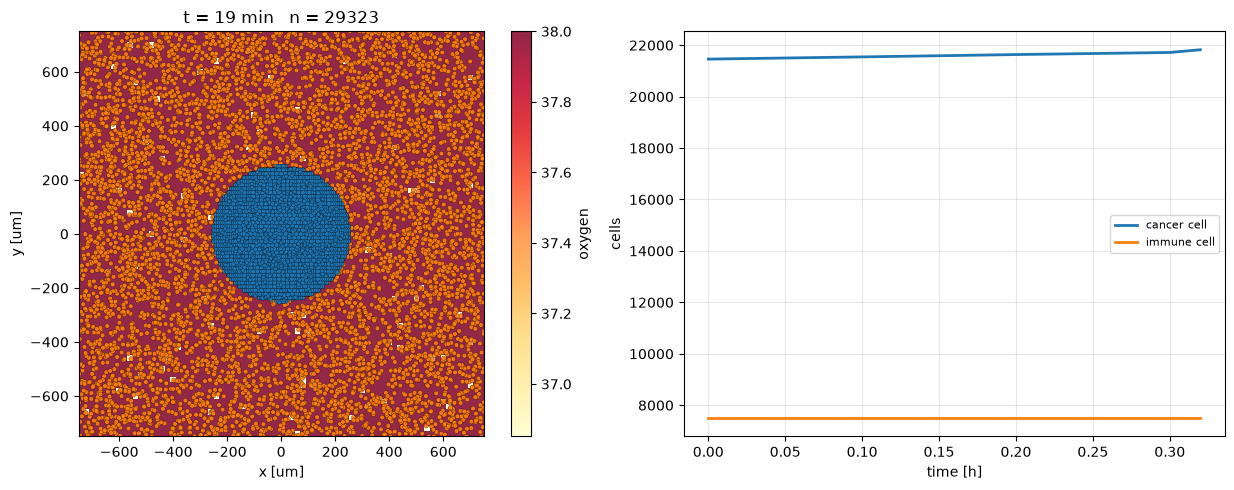

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_cells(sim, substrate='oxygen', ax=axes[0])
viz.plot_populations(scalars, ax=axes[1])
plt.tight_layout()

## 4. Steer it while it runs

Change the state mid-run and carry on from where you are. In the file workflow
this is a new XML and a new run from t=0, or custom C++ and a recompile.

mean oxygen 32.8 -> 32.8


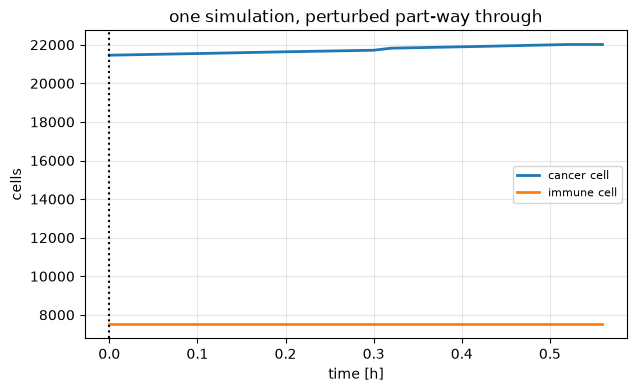

In [8]:
before = sim.microenvironment['oxygen'].mean()
sim.microenvironment.density[..., 0] = 0.0      # remove oxygen everywhere
sim.run(until=sim.t + 14.39, record_every=6)
after = sim.microenvironment['oxygen'].mean()
print(f'mean oxygen {before:.3g} -> {after:.3g}')
viz.plot_populations(sim.scalars)
plt.axvline(sim.scalars.times[0] / 60, ls=':', c='k')
plt.title('one simulation, perturbed part-way through');

## 5. Two futures from one state

`branch()` is a deepcopy of the whole simulation, because all of the state is
Python. PhysiCell keeps its state in process globals, so a second simulation in
the same process is impossible there and a counterfactual means re-running from
the beginning with a different input file.

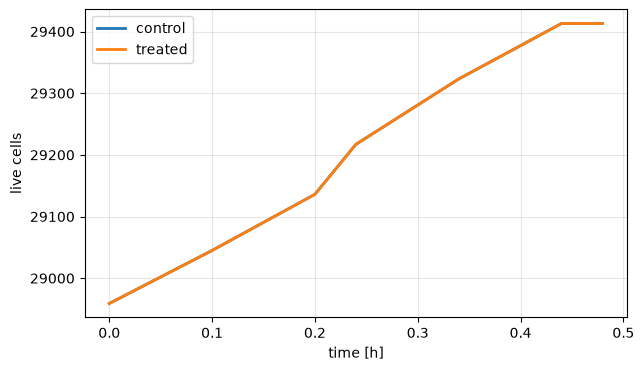

In [9]:
base = pc.Simulation(model, seed=model.random_seed)
if not base.cells.n:
    pc.initial.apply(base)
base.run(until=14.39, record_every=6)

control = base.branch()
treated = base.branch()
treated.microenvironment.density[..., 0] *= 0.1   # 90% knock-down
control.run(until=control.t + 14.39, record_every=6)
treated.run(until=treated.t + 14.39, record_every=6)

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in (('control', control.scalars), ('treated', treated.scalars)):
    total = np.sum([v for v in s.counts.values()], axis=0)
    ax.plot(np.asarray(s.times) / 60, total, lw=2, label=name)
ax.set_xlabel('time [h]'); ax.set_ylabel('live cells'); ax.legend(); ax.grid(alpha=0.3);

## 6. Logic the rules grammar cannot express

A CBHG rule is a Hill function of one cell's own signals: it cannot see where a
cell is, or how it ranks against the rest of the population. A hook is arbitrary
Python over the whole population, called once per phenotype step on arrays, so
both become possible -- and still no C++.

In [10]:
probe = pc.Simulation(model, seed=model.random_seed)
if not probe.cells.n:
    pc.initial.apply(probe)
log = []

@probe.hook('phenotype', cell_type='cancer cell')
def spatial_and_population_relative(ctx):
    p = ctx.signals['pressure']
    crowded = p >= np.quantile(p, 0.9) if ctx.n > 1 else np.zeros(ctx.n, bool)
    left = ctx.position[:, 0] < 0
    # population-relative: the most crowded tenth stops cycling
    ctx.behaviors['cycle entry'] = np.where(crowded, 0.0,
                                            ctx.behaviors['cycle entry'])
    # spatial: cells in the left half of the domain stop migrating
    ctx.behaviors['migration speed'] = np.where(left, 0.0,
                                                ctx.behaviors['migration speed'])
    log.append((ctx.t, int(crowded.sum()), float(left.mean())))

probe.run(until=14.39, record_every=6)
c = probe.cells
mine = c.view('type_idx') == probe.type_index['cancer cell']
left = mine & (c.view('position')[:, 0] < 0)
right = mine & (c.view('position')[:, 0] >= 0)
print(f'hook fired {len(log)} times, one call per phenotype step for all {mine.sum()} cells')
print(f"  mean migration speed   left {c.view('motility_speed')[left].mean():.3f}   right {c.view('motility_speed')[right].mean():.3f}")
print(f"  mean cycle entry rate  crowded decile is held at 0; population mean {c.view('cycle_entry_rate')[mine].mean():.3e}")

hook fired 3 times, one call per phenotype step for all 21717 cells
  mean migration speed   left 0.000   right 0.249
  mean cycle entry rate  crowded decile is held at 0; population mean 0.000e+00


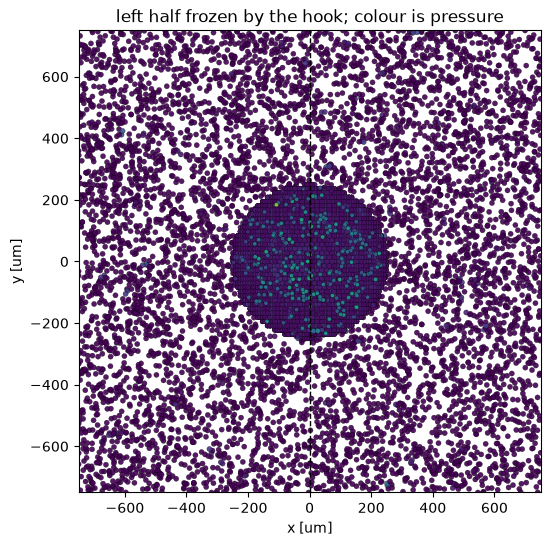

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_cells(probe, color_by='pressure', ax=ax)
ax.axvline(0, ls='--', c='k', lw=1)
ax.set_title('left half frozen by the hook; colour is pressure');

## 7. A sweep in one process

Varying the cycle transition rate of cancer cell, with replicates. No files, no subprocesses, no recompilation --
the models and the simulations are objects, so N of them are just N objects.

*That parameter was not chosen by hand.* The generator screened every knob this
model exposes -- rule half-maxes and saturated responses, cycle and death rates,
migration speed, substrate decay -- at half and double its published value, and
kept the one that moved an outcome most (126% spread at x4). Most knobs
in a
published model move nothing at its own parameters, which is itself worth
knowing before you spend a cluster on a sweep.

In [12]:
def change(m, value):
    m.cell_type('cancer cell').cycle.transition_rates[(0, 0)] = value

df, runs = pc.sweep(model, change, [0.00018, 0.00072, 0.00288], until=14.39,
                    replicates=2, progress=True)
df[['value', 'replicate', 'cells', 'births', 'deaths', 'spread_um',
    'mean_pressure', 'wall_s']]

       0.00018  rep 0  ->   29030 cells (16.9 s)


       0.00018  rep 1  ->   29033 cells (17.2 s)


       0.00072  rep 0  ->   29237 cells (17.2 s)


       0.00072  rep 1  ->   29252 cells (16.6 s)


       0.00288  rep 0  ->   30106 cells (15.8 s)


       0.00288  rep 1  ->   30083 cells (18.0 s)


,value,replicate,cells,births,deaths,spread_um,mean_pressure,wall_s
0,0.00018,0,29030,71,0,414.77,0.7817,16.93
1,0.00018,1,29033,74,0,414.72,0.7816,17.16
2,0.00072,0,29237,278,0,413.61,0.8414,17.24
3,0.00072,1,29252,293,0,413.58,0.8459,16.59
4,0.00288,0,30106,1147,0,408.91,1.0635,15.82
5,0.00288,1,30083,1124,0,409.08,1.0614,18.04


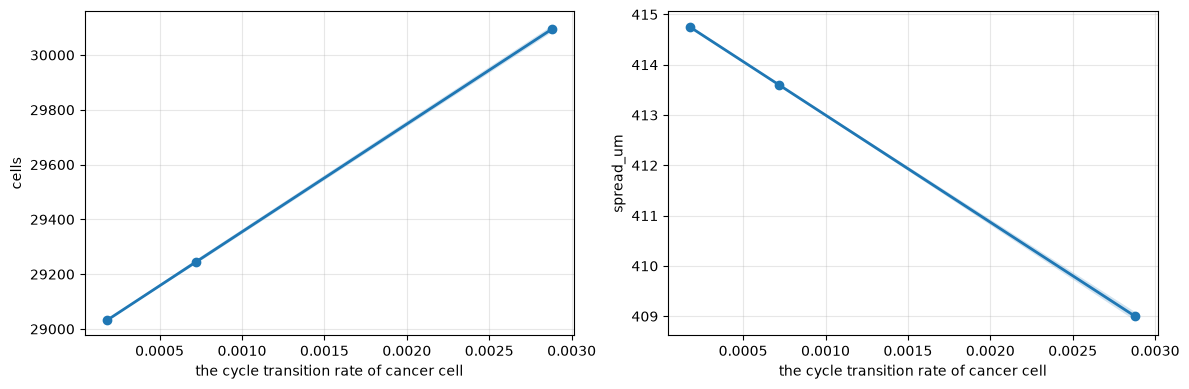

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pc.plot_sweep(df, 'cells', ax=axes[0], label='live cells')
pc.plot_sweep(df, 'spread_um', ax=axes[1], label='spread (RMS radius)')
axes[0].set_xlabel('the cycle transition rate of cancer cell'); axes[1].set_xlabel('the cycle transition rate of cancer cell')
plt.tight_layout()

## 8. Stop when something happens

A question like *when* does this model cross a level is a stopping condition
here, and a post-hoc search through saved snapshots otherwise.

The level is read off the run in section 3 rather than guessed, so the condition
is an event this model really reaches. An earlier version of this notebook picked
a threshold a priori and ran to its limit in 19 of 37 projects, demonstrating
nothing.

In [14]:
import numpy as np
h = sim.scalars
t = np.asarray(h.times, dtype=float)
# sections 4-6 steered this same sim, so calibrate on the untouched part
keep = t <= 19.19
t = t[keep]
series = {}
if h.counts:
    series['live cells'] = np.asarray([sum(v) for v in zip(*h.counts.values())],
                                      dtype=float)[keep]
series['dead cells'] = np.asarray(h.dead, dtype=float)[keep]
series['cumulative births'] = np.asarray(h.births, dtype=float)[keep]
series['cumulative deaths'] = np.asarray(h.deaths, dtype=float)[keep]
for _s, _v in h.mean_substrate.items():
    series[f'mean {_s}'] = np.asarray(_v, dtype=float)[keep]

def moved(v):
    scale = max(float(np.abs(v).max()), 1e-12)
    return max(abs(v[-1] - v[0]), v.max() - v.min()) / scale

name, y = max(series.items(), key=lambda kv: moved(kv[1]))
y0, lo, hi, end = float(y[0]), float(y.min()), float(y.max()), float(y[-1])
if end != y0:                      # 60% of the way to where it ended
    rising, level = end > y0, y0 + 0.6 * (end - y0)
else:                              # it came back: aim at the far extreme
    rising = (hi - y0) >= (y0 - lo)
    level = y0 + 0.6 * ((hi - y0) if rising else (lo - y0))
live = moved(y) > 0
print(f'{sum(moved(v) > 0 for v in series.values())} of {len(series)} recorded observables moved')
if live:
    crossed = t[np.argmax((y >= level) if rising else (y <= level))]
    print(f'watching {name}: the baseline crossed {level:.4g} at t = {crossed:.1f} min')
else:
    print('nothing this model records changes over the demo window')

3 of 6 recorded observables moved
watching cumulative births: the baseline crossed 154.8 at t = 12.0 min


In [15]:
readers = {'live cells': lambda s: float((s.cells.view('dead') == 0).sum()),
           'dead cells': lambda s: float((s.cells.view('dead') == 1).sum()),
           'cumulative births': lambda s: float(s._births),
           'cumulative deaths': lambda s: float(s._deaths)}
for _s in model.substrate_names:
    readers[f'mean {_s}'] = (lambda n: lambda s: float(s.microenvironment[n].mean()))(_s)
read = readers[name]

watch = pc.Simulation(model, seed=model.random_seed)
if not watch.cells.n:
    pc.initial.apply(watch)
limit = 76.76
watch.run(until=limit, record_every=6,
          stop_when=(lambda s: (read(s) >= level) if rising else (read(s) <= level))
                    if live else None)
print(f'stopped at t = {watch.t:.1f} min of a {limit:.0f} min limit, {name} = {read(watch):.4g}')
if live:
    assert watch.t < limit, 'the stopping condition never fired'

stopped at t = 6.0 min of a 77 min limit, cumulative births = 177
